In [1]:
import sys
import os
import glob
import importlib

import tqdm

In [2]:
import numpy as np
import pandas as pd
import scipy.constants as sc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import corner

%matplotlib inline

In [3]:
import multiprocessing

print(multiprocessing.cpu_count())
# os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={multiprocessing.cpu_count()}"
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count=4"

64


In [4]:
import jax
jax.config.update('jax_enable_x64', True)

import jax.random
import jax.numpy as jnp

importlib.reload(jax)
importlib.reload(jax.random)
importlib.reload(jnp)

<module 'jax.numpy' from '/DATA/CARINA_4/mit227/conda_envs/envs/carina_env/lib/python3.13/site-packages/jax/numpy/__init__.py'>

In [5]:
import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro
importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.aldm_signal)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)

<module 'discovery.prior' from '/h/mit227/discovery-ppa/src/discovery/prior.py'>

In [6]:
from discovery import prior
importlib.reload(prior)
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [7]:
psr = ds.Pulsar.read_feather('/DATA/CARINA_4/mit227/subband_PA_data/J1645-0317.PA.head_derot.minusSBmean.feather', json_metadata=False)
psr.dist0 = 4.0 # kpc
print(psr)

<Pulsar J1645-0317: 576 res, 0 pars>


In [8]:
with np.printoptions(threshold=sys.maxsize):
    print(np.degrees(psr.residuals))
    print(np.degrees(psr.toaerrs))

[ 1.50393987e+00  5.99360871e+00             nan             nan
             nan             nan             nan  3.47204899e+00
  4.46468746e+00             nan             nan -6.49756749e+00
             nan             nan  6.35263322e+00  3.68576427e+00
  1.99418949e+00             nan             nan -3.52201546e+01
             nan             nan  8.08683262e+00  8.47152394e+00
  4.15291832e+00             nan             nan -4.26822153e+00
             nan             nan  1.20411669e+01  9.50576041e+00
  5.04548570e+00             nan             nan  3.64915757e+01
             nan             nan  5.28968862e+00  7.04478477e+00
  1.81139416e+00             nan             nan  1.78134837e-01
             nan             nan  2.18034948e+01  2.62403979e+00
  6.05370267e-01             nan             nan  1.93087337e-01
             nan             nan  5.81326646e+00  2.74537186e+00
 -5.30659597e-01             nan             nan  8.57845344e-01
             nan         

In [9]:
with np.printoptions(threshold=sys.maxsize):
    print(psr.freqs)
    print(psr.subbands)

[1070.479 1430.815 1776.705 2106.756 2765.381 3258.068 3809.371 1042.099
 1413.417 1820.535 2107.81  2762.371 3258.315 3800.755  804.571 1057.465
 1408.065 1776.056 2106.872 2764.755 3258.778 3808.671  806.166 1062.578
 1415.591 1778.019 2106.352 2764.755 3257.058 3804.771  802.99  1064.484
 1434.852 1776.059 2107.307 2764.814 3258.773 3804.262  806.285 1060.281
 1414.844 1778.524 2105.913 2763.981 3258.502 3803.035  810.083 1062.442
 1429.303 1780.097 2107.9   2766.313 3256.787 3806.617  789.722 1062.858
 1419.202 1780.129 2105.479 2777.291 3261.363 3801.275  827.15  1080.906
 1419.258 1770.272 2106.443 2767.407 3258.003 3806.588  791.192 1051.25
 1433.537 1784.073 2107.333 2775.086 3261.754 3807.194  812.651 1059.113
 1409.192 1782.2   2107.438 2764.957 3258.068 3806.71   767.055 1084.264
 1409.905 1779.966 2105.443 2764.755 3258.068 3803.038 1121.    1466.422
 1775.517 2107.479 2761.663 3258.062 3806.297  797.5   1065.93  1416.243
 1774.793 2106.887 2764.669 3255.178 3804.665  811.9

In [10]:
obs_PA_dict = {}
for obs in psr.obsnames:
    mask = psr.obsnames == obs
    obs_sbs = psr.subbands[mask]
    obs_PAs = psr.residuals[mask]

    PA_list_for_dict = []
    i_in_orig = 0
    for sb in range(1,8+1):
        if sb in obs_sbs:
            PA_list_for_dict.append(obs_PAs[i_in_orig])
            i_in_orig += 1
        else:
            PA_list_for_dict.append(np.nan)

    obs_PA_dict[obs] = PA_list_for_dict

pd.set_option('display.max_rows', None)
df = pd.DataFrame(obs_PA_dict, index=range(1,8+1)).T
df

,1,2,3,4,5,6,7,8
uwl_190217_223839_b4,NaN,0.026249,0.104608,NaN,NaN,NaN,NaN,NaN
uwl_190314_220116_b4,NaN,0.060599,0.077923,NaN,NaN,-0.113404,NaN,NaN
uwl_190505_180752_b4,0.110874,0.064329,0.034805,NaN,NaN,-0.614708,NaN,NaN
uwl_190612_160445_b4,0.141142,0.147856,0.072482,NaN,NaN,-0.074495,NaN,NaN
uwl_190706_142355_b4,0.210158,0.165907,0.088060,NaN,NaN,0.636898,NaN,NaN
uwl_190728_124534_b4,0.092322,0.122955,0.031615,NaN,NaN,0.003109,NaN,NaN
uwl_190824_110229_b4,0.380543,0.045798,0.010566,NaN,NaN,0.003370,NaN,NaN
uwl_190918_092107_b4,0.101461,0.047916,-0.009262,NaN,NaN,0.014972,NaN,NaN
uwl_191006_085553_b4,0.455779,0.109349,0.045869,NaN,NaN,0.199247,NaN,NaN
uwl_191103_064330_b4,0.257022,-0.137550,-0.007867,NaN,NaN,0.047368,NaN,NaN


In [11]:
print(psr.backend_flags)

['P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL'
 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_UWL' 'P574_

In [12]:
importlib.reload(ds)
importlib.reload(ds.signals)
importlib.reload(ds.aldm_signal)
importlib.reload(ds.matrix)

<module 'discovery.matrix' from '/h/mit227/discovery-ppa/src/discovery/matrix.py'>

In [13]:
print(ds.makegp_ecorr_simple(psr).Phi)
print(ds.makegp_ecorr_simple(psr).Phi.getN)
print(ds.makegp_ecorr_simple(psr).Phi.getN.params)
print(ds.makegp_ecorr_simple(psr).Phi.getN({
    'J0835-4510_log10_ecorr': -1.0
    }))

<function makegp_ecorr_simple.<locals>.getphi at 0x7f48b80df4c0>
['J1645-0317_log10_ecorr']


KeyError: 'J1645-0317_log10_ecorr'

In [131]:
# print(ds.makegp_fourier(psr, ds.powerlaw, 30).F)
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi)
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.getN)
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.getN.params)
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.getN.type)
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.getN({
    'J0835-4510_fourierGP_log10_A': -8.3, 
    'J0835-4510_fourierGP_gamma': 1.8
    }))
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.make_inv())
print(ds.makegp_fourier(psr,ds.powerlaw,3).Phi.make_inv()({
    'J0835-4510_fourierGP_log10_A': -8.3, 
    'J0835-4510_fourierGP_gamma': 1.8
    }))

<function makegp_fourier.<locals>.priorfunc at 0x7fb5dc920a40>
['J0835-4510_fourierGP_log10_A', 'J0835-4510_fourierGP_gamma']
None
[0.00109446 0.00109446 0.0003143  0.0003143  0.00015149 0.00015149]
<function NoiseMatrix1D_var.make_inv.<locals>.inv at 0x7fb5643222a0>
(Array([[ 913.69194703,    0.        ,    0.        ,    0.        ,
           0.        ,    0.        ],
       [   0.        ,  913.69194703,    0.        ,    0.        ,
           0.        ,    0.        ],
       [   0.        ,    0.        , 3181.66015666,    0.        ,
           0.        ,    0.        ],
       [   0.        ,    0.        ,    0.        , 3181.66015666,
           0.        ,    0.        ],
       [   0.        ,    0.        ,    0.        ,    0.        ,
        6601.12650473,    0.        ],
       [   0.        ,    0.        ,    0.        ,    0.        ,
           0.        , 6601.12650473]], dtype=float64), Array(-47.35529495, dtype=float64))


In [132]:
print(ds.makegp_aldm_psr(psr,-23.0).F)
print(ds.makegp_aldm_psr(psr,-23.0).Phi)
print(ds.makegp_aldm_psr(psr,-23.0).Phi.getN)
print(ds.makegp_aldm_psr(psr,-23.0).Phi.getN.params)
# print(ds.makegp_aldm_psr(psr,-23.0).Phi.getN.type)
print(ds.makegp_aldm_psr(psr,-23.0).Phi.getN({
    'log10_Sa': -1.0
    }))
print(ds.makegp_aldm_psr(psr,-23.0).Phi.make_inv())
print(ds.makegp_aldm_psr(psr,-23.0).Phi.make_inv()({
    'log10_Sa': -1.0
    }))

[[-0.99608496 -0.08840111]
 [-0.99608496 -0.08840111]
 [-0.99608496 -0.08840111]
 ...
 [ 0.87711422 -0.48028184]
 [ 0.86873629 -0.49527493]
 [ 0.86873629 -0.49527493]]
<function makegp_aldm_psr.<locals>.getphi at 0x7fb5dc920a40>
['log10_Sa']
[[ 0.01936653 -0.        ]
 [ 0.          0.01936653]]
<function NoiseMatrix2D_var.make_inv.<locals>.inv at 0x7fb5643222a0>
(Array([[51.63548362,  0.        ],
       [ 0.        , 51.63548362]], dtype=float64), Array(-7.88841821, dtype=float64))


In [133]:
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).F)
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi)
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi.getN)
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi.getN.params)
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi.getN({
    'J0835-4510_fftcovGP_log10_A': -8.3, 
    'J0835-4510_fftcovGP_gamma': 1.8
    }))
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi.make_inv())
print(ds.makegp_fftcov(psr, ds.powerlaw, 3).Phi.make_inv()({
    'J0835-4510_fftcovGP_log10_A': -8.3, 
    'J0835-4510_fftcovGP_gamma': 1.8
    }))

[[1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.00000000e+00 7.75378622e-11 0.00000000e+00]
 [1.00000000e+00 2.38152834e-11 0.00000000e+00]
 ...
 [0.00000000e+00 9.16439155e-03 9.90835608e-01]
 [0.00000000e+00 8.40454145e-11 1.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
<function makegp_fourier.<locals>.priorfunc at 0x7fb564320ea0>
['J0835-4510_fftcovGP_log10_A', 'J0835-4510_fftcovGP_gamma']
[[4.05325995e-05 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 4.05325995e-05 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 4.05325995e-05]]
<function NoiseMatrix2D_var.make_inv.<locals>.inv at 0x7fb564320ea0>
(Array([[24671.49927534,     0.        ,     0.        ],
       [    0.        , 24671.49927534,     0.        ],
       [    0.        ,     0.        , 24671.49927534]], dtype=float64), Array(-30.34021194, dtype=float64))


In [134]:
# %timeit ds.makegp_ecorr_simple(psr) 
# %timeit ds.makegp_erm(psr)

In [135]:
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True, ecorr=True)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True), ds.makegp_erm(psr)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True, ecorr=True), ds.makegp_erm(psr)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr), ds.makegp_erm(psr)])
# %timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr), ds.makegp_erm(psr), ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')])


In [136]:
%timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True)])
%timeit ds.PulsarLikelihood([psr.residuals, ds.makenoise_measurement(psr, tnequad=True, log_efac=True)])

92.9 μs ± 370 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
93.1 μs ± 3.35 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [137]:
# %timeit [ds.makenoise_measurement(psr, tnequad=True)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True, ecorr=True)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True), ds.makegp_erm(psr)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True, ecorr=True), ds.makegp_erm(psr)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr), ds.makegp_erm(psr)]
# %timeit [ds.makenoise_measurement(psr, tnequad=True), ds.makegp_ecorr(psr), ds.makegp_erm(psr), ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')]

[]
['uwl_261001_092128', 'uwl_260831_113506', 'uwl_260730_133454', 'uwl_260703_152428', 'uwl_260605_170506', 'uwl_260503_192336', 'uwl_260402_212351', 'uwl_260307_231548', 'uwl_260213_002841', 'uwl_260113_024147', 'uwl_251207_051241', 'uwl_251109_064830', 'uwl_251011_085123', 'uwl_250914_103359', 'uwl_250815_122755', 'uwl_250516_181828', 'uwl_250427_193731', 'uwl_250329_213305', 'uwl_250227_232633', 'uwl_250126_013905', 'uwl_241216_041247', 'uwl_241112_062809', 'uwl_241006_085245', 'uwl_240908_104643', 'uwl_240809_124427', 'uwl_240716_141935', 'uwl_240704_150426', 'uwl_240531_165633', 'uwl_240429_192110', 'uwl_240401_211838', 'uwl_240321_214333', 'uwl_240215_002040', 'uwl_240108_025947', 'uwl_231221_032615', 'uwl_231114_062720', 'uwl_231006_084738', 'uwl_230908_103607', 'uwl_230806_130554', 'uwl_230712_142711', 'uwl_230605_165154', 'uwl_230514_183927', 'uwl_230403_211440', 'uwl_230329_213002', 'uwl_230225_232508', 'uwl_230121_014053', 'uwl_221218_035224', 'uwl_221119_061706', 'uwl_2210

[]

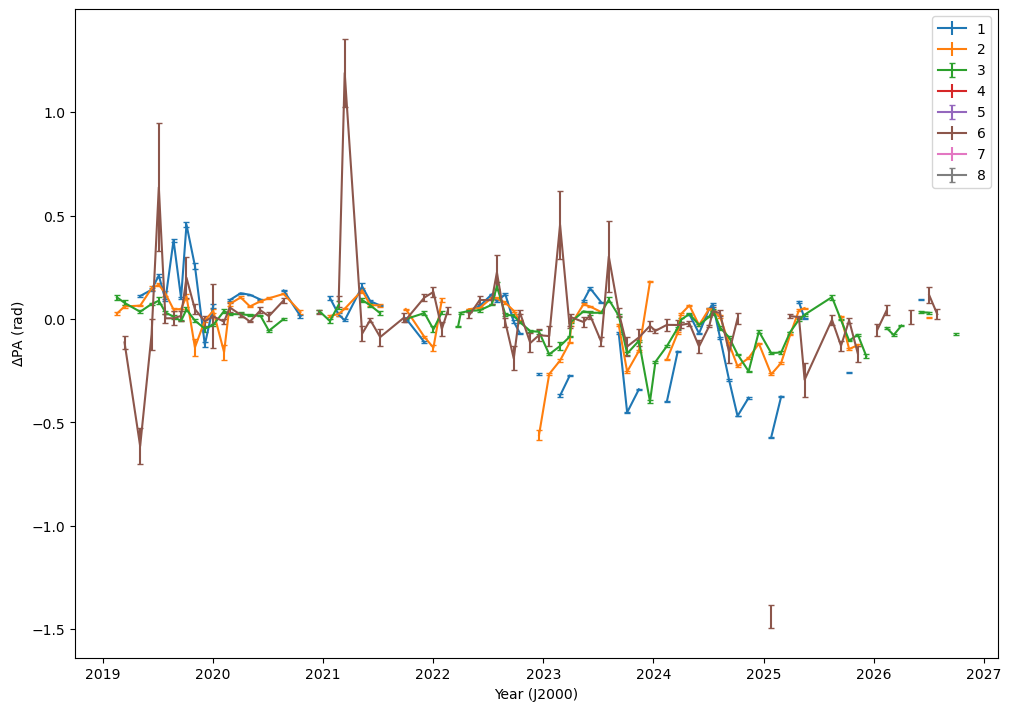

In [14]:
from astropy.time import Time

fig, ax = plt.subplots(1, 1, figsize=(10, 7), layout='constrained')

badobs_path=f'{os.environ.get("P574")}/bad.verybad'
bad_obs = np.loadtxt(badobs_path, dtype=str, usecols=[0,1])
psr_bad_obs = bad_obs[:,1][bad_obs[:,0] == psr.name]
print(psr_bad_obs)

all_obs_of_pulsar = sorted(np.concatenate((psr.obsnames_unique, psr_bad_obs)))
print(all_obs_of_pulsar[::-1])

for sb in range(1,8+1):
    mask = psr.subbands == sb
    sb_t = Time(psr.toas[mask], format='unix', scale='utc')
    # print(sb_t.jyear-sb_t.decimalyear)
    sb_obsnames = psr.obsnames[mask]
    sb_PAs = psr.residuals[mask]
    sb_PAerrs = psr.toaerrs[mask]

    mask2 = np.zeros_like(sb_PAs, dtype=bool)
    i = 0
    for obsname in all_obs_of_pulsar:
        if obsname in sb_obsnames:
            mask2[i] = True
            i += 1
        else:
            ax.errorbar(sb_t[mask2].jyear,#.mjd-60000,
                        sb_PAs[mask2],
                        sb_PAerrs[mask2],
                        capsize=2.5, c=f'C{sb-1}')
            mask2 = np.zeros_like(sb_PAs, dtype=bool)

    ax.errorbar(sb_t[mask2].jyear,#.mjd-60000,
                sb_PAs[mask2],
                sb_PAerrs[mask2],
                capsize=2.5, label=sb, c=f'C{sb-1}')

# ax.set_xlabel('MJD - 60000')
ax.set_xlabel('Year (J2000)')
ax.set_ylabel('$\\Delta$PA (rad)')
ax.legend()
plt.plot()

In [139]:
print(str(b'J0835-4510'))

b'J0835-4510'


In [140]:
type(psr.residuals)

numpy.ndarray

#### Measurement noise only

In [141]:
m = ds.PulsarLikelihood([psr.residuals,#np.nan_to_num(psr.residuals, nan=0.0),
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True)]) # tnequad ensures EQUAD isn't scaled by EFAC

In [142]:
bounds = [prior.getprior_uniform(p) for p in m.logL.params]
print(bounds)

[[-1, 2], [-4, -1.5]]


In [143]:
p0 = ds.sample_uniform(m.logL.params)
print(p0)
print(m.logL(p0))

{'J0835-4510_P574_UWL_efac_log10': -0.7097778777299711, 'J0835-4510_P574_UWL_log10_tnequad': -3.034974484967799}
-2373246.8885533377


#### Add ECORR noise (GP), free params

In [144]:
m_ecorr = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr)])
print(m_ecorr.logL.params)

['J0835-4510_P574_UWL_efac_log10', 'J0835-4510_P574_UWL_log10_ecorr', 'J0835-4510_P574_UWL_log10_tnequad']


In [145]:
p0 = ds.sample_uniform(m_ecorr.logL.params)
print(p0)
print(f'w/  ECORR: {m_ecorr.logL(p0)}')
print(f'w/o ECORR: {m.logL(p0)}')

{'J0835-4510_P574_UWL_efac_log10': 0.9438073667722957, 'J0835-4510_P574_UWL_log10_ecorr': -2.7406828963931025, 'J0835-4510_P574_UWL_log10_tnequad': -2.2697233199767375}
w/  ECORR: -48177.82808402243
w/o ECORR: -64352.861780867446


#### Add RM noise

In [146]:
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
print(m_RM.logL.params)

['J0835-4510_P574_UWL_efac_log10', 'J0835-4510_P574_UWL_log10_ecorr', 'J0835-4510_P574_UWL_log10_tnequad', 'J0835-4510_log10_erm', 'J0835-4510_rmgp_gamma', 'J0835-4510_rmgp_log10_A']


In [147]:
p0 = ds.sample_uniform(m_RM.logL.params)
print(p0)
print(f'Noise:          {m.logL(p0):e}')
print(f'Noise+ECORR:    {m_ecorr.logL(p0):e}')
print(f'Noise+ECORR+RM: {m_RM.logL(p0):e}')

{'J0835-4510_P574_UWL_efac_log10': 1.277031910748482, 'J0835-4510_P574_UWL_log10_ecorr': -1.6391869139196014, 'J0835-4510_P574_UWL_log10_tnequad': -2.2061896237278553, 'J0835-4510_log10_erm': -2.4843131402658463, 'J0835-4510_rmgp_gamma': 6.505264444794487, 'J0835-4510_rmgp_log10_A': -9.946258375460781}
Noise:          -4.542127e+04
Noise+ECORR:    -1.820729e+04
Noise+ECORR+RM: -1.493912e+03


In [148]:
# sampler = m_RM.sample

# fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

# for i in range(2):
#     for j in range(2):
#         ax = axs[i][j]

#         # fix parameters to reasonable value
#         params = {
#             'J0835-4510_P574_UWL_efac':10.000,
#             'J0835-4510_P574_UWL_log10_ecorr':-5.000,
#             'J0835-4510_P574_UWL_log10_tnequad':-3.000+(i+2*j)/4,
#             'J0835-4510_rmgp_gamma':0.986,
#             'J0835-4510_rmgp_log10_A':-8.121
#             }

#         # should jit the sampler if simulating many datasets
#         key = ds.rngkey(42)#+i+2*j)
#         key, res = sampler(key, params)

#         for sb in range(1,8+1):
#             mask = psr.subbands == sb
#             t = Time(psr.toas[mask], format='unix', scale='utc')
#             ax.errorbar(t.mjd-60000, 
#                         # np.degrees(
#                             res[mask],
#                             # ), 
#                         # np.degrees(
#                             psr.toaerrs[mask],
#                             # ), 
#                         capsize=2.5, label=sb)

#         if i==1:
#             ax.set_xlabel('MJD - 60000')
#         if j==0:
#             ax.set_ylabel('$\\Delta$PA (rad)')
#         ax.set_title(f'J0835-4510_P574_UWL_log10_tnequad: {params['J0835-4510_P574_UWL_log10_tnequad']}')
#         ax.legend()

# plt.plot()

#### ALDM Signal

In [13]:
sc.hbar*sc.value('joule-electron volt relationship')*1e-9 * sc.c*1e2

1.973269804593025e-14

In [10]:
print(f'm^-1 = {sc.value('inverse meter-electron volt relationship')} eV')
print(f'cm^-1 = {1e2*sc.value('inverse meter-electron volt relationship')*1e-9} GeV')

m^-1 = 1.2398419843320026e-06 eV
cm^-1 = 1.2398419843320026e-13 GeV


In [149]:
m_aldm = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_aldm_psr(psr,-23.0)
                         ])
print(m_aldm.logL.params)

['J0835-4510_P574_UWL_efac_log10', 'J0835-4510_P574_UWL_log10_ecorr', 'J0835-4510_P574_UWL_log10_tnequad', 'J0835-4510_log10_erm', 'J0835-4510_rmgp_gamma', 'J0835-4510_rmgp_log10_A', 'log10_Sa']


In [150]:
logL = m_aldm.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[-1, 2], [-3, -1], [-4, -1.5], [-4, -0.5], [0, 7], [-14, -5], [-8, 2]]


In [151]:
jax.devices()

[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]

In [ ]:
n_chains = 1
mcmc = infer.MCMC(infer.NUTS(numpyro_model), num_chains=n_chains,
                     num_warmup=75, num_samples=75)
# mcmc.warmup(jax.random.PRNGKey(42)#,
            # init_params={
            # 'J0835-4510_P574_UWL_efac':1.000,
            # 'J0835-4510_P574_UWL_log10_ecorr':-1.569,
            # 'J0835-4510_P574_UWL_log10_tnequad':-3.000,
            # 'J0835-4510_rmgp_gamma':1.249,
            # 'J0835-4510_rmgp_log10_A':-8.096
            # }
            # )
mcmc.run(jax.random.PRNGKey(43))

sample: 100%|██████████| 150/150 [1:08:34<00:00, 27.43s/it, 127 steps of size 1.28e-02. acc. prob=0.97]


In [ ]:
raw_samples = mcmc.get_samples()['raw']
print(len(raw_samples))

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')

75
J0835-4510_P574_UWL_efac       mean=+9.730  std=0.297  bounds=[0.1, 10]
J0835-4510_P574_UWL_log10_ecorr mean=-1.922  std=0.039  bounds=[-3, -1]
J0835-4510_P574_UWL_log10_tnequad mean=-2.068  std=0.015  bounds=[-4, -1.5]
J0835-4510_log10_erm           mean=-1.435  std=0.035  bounds=[-4, -0.5]
J0835-4510_rmgp_gamma          mean=+1.601  std=0.270  bounds=[0, 2]
J0835-4510_rmgp_log10_A        mean=-8.294  std=0.100  bounds=[-9, -7]
{'J0835-4510_P574_UWL_efac': Array(9.7301686, dtype=float64), 'J0835-4510_P574_UWL_log10_ecorr': Array(-1.92180645, dtype=float64), 'J0835-4510_P574_UWL_log10_tnequad': Array(-2.06784065, dtype=float64), 'J0835-4510_log10_erm': Array(-1.43473427, dtype=float64), 'J0835-4510_rmgp_gamma': Array(1.60076064, dtype=float64), 'J0835-4510_rmgp_log10_A': Array(-8.29397314, dtype=float64)}
3.362979e+03


<class 'jaxlib._jax.ArrayImpl'>


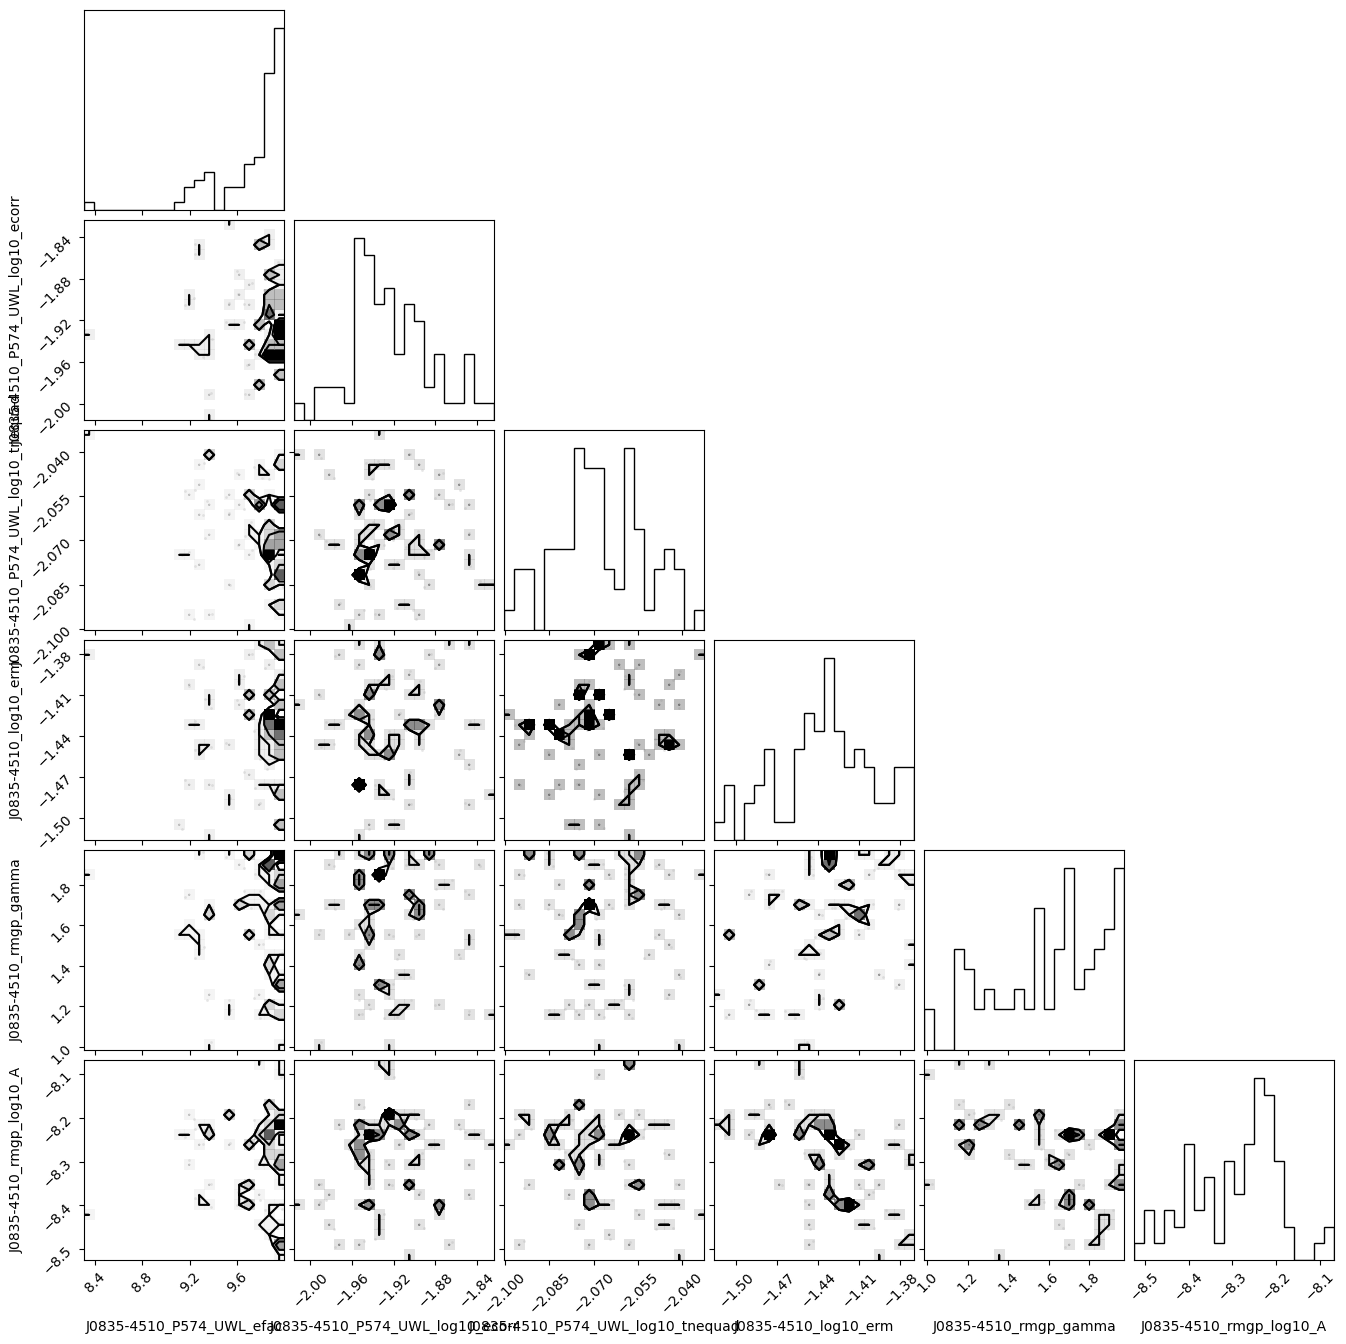

In [ ]:
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

[]

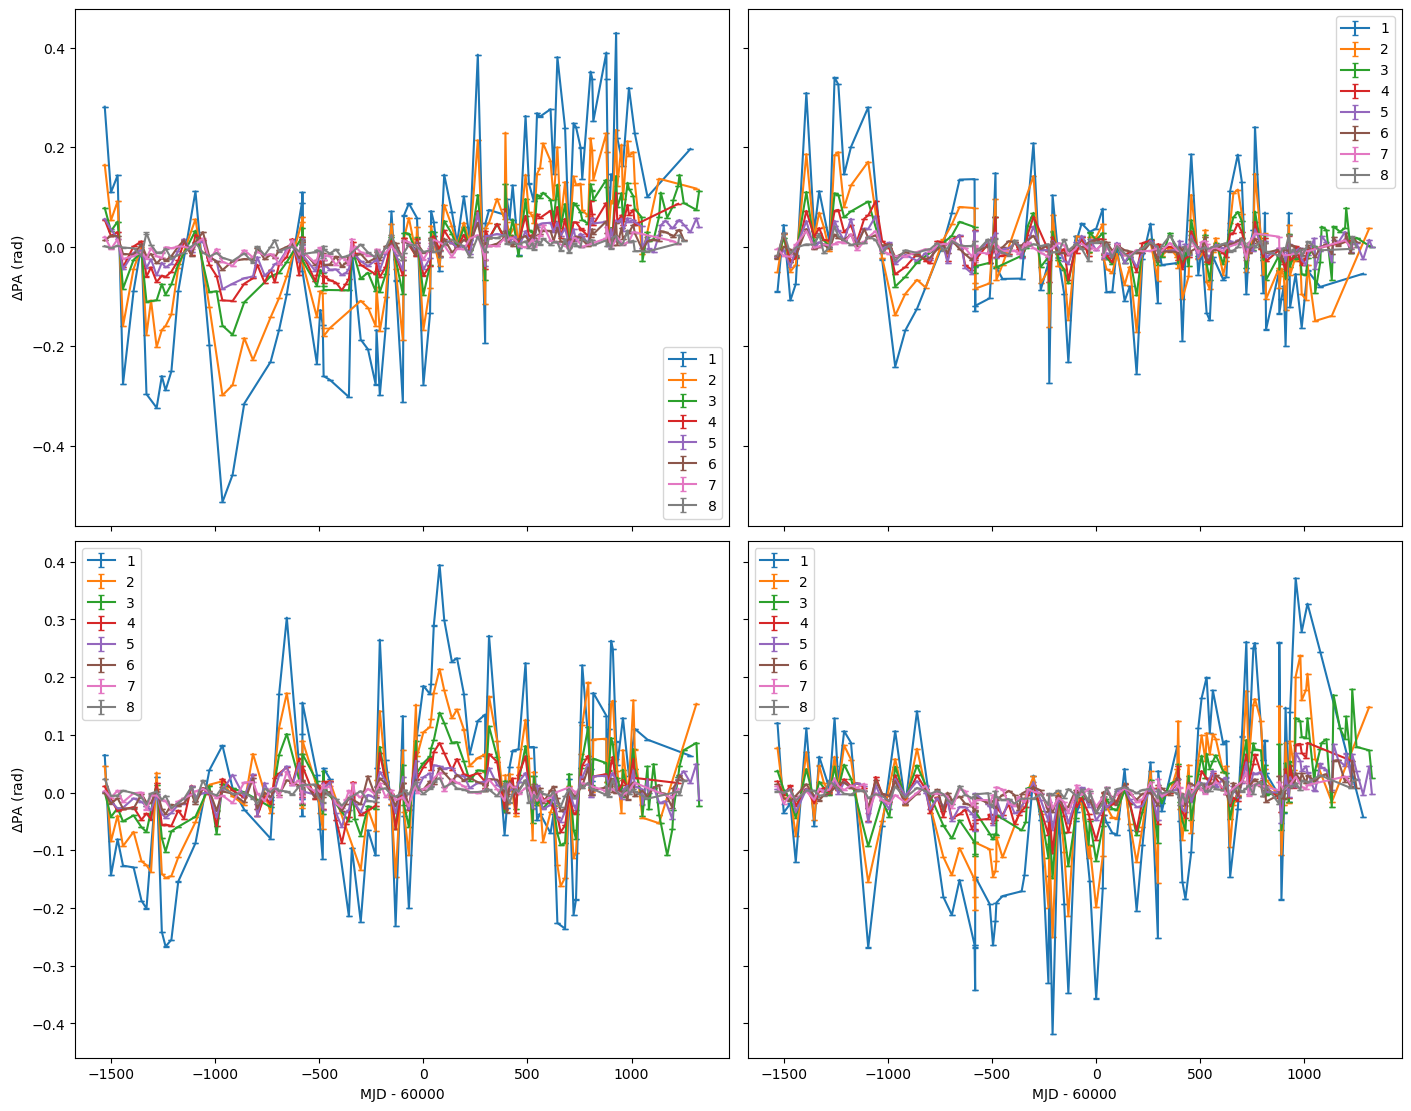

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### Add achromatic red noise

In [ ]:
m_red = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement_simple(psr),
                         ds.makegp_ecorr_simple(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, name='rednoise')
                         ])
print(m_red.logL.params)

['J0835-4510_efac', 'J0835-4510_log10_ecorr', 'J0835-4510_log10_t2equad', 'J0835-4510_rednoise_gamma', 'J0835-4510_rednoise_log10_A', 'J0835-4510_rmgp_gamma', 'J0835-4510_rmgp_log10_A']


In [ ]:
from discovery import prior
from discovery.params import Params, make_layout

import numpyro
from numpyro import infer, distributions as dist

In [ ]:
logL = m_red.logL

# static layout shared by every Params built inside the model
layout, size = make_layout(logL.params)

# flat uniform bounds, one entry per (scalar) parameter
bounds = [prior.getprior_uniform(p) for p in logL.params]
print(bounds)
lo = jnp.array([b[0] for b in bounds])
hi = jnp.array([b[1] for b in bounds])

def numpyro_model():
    raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
    numpyro.factor('logl', logL(Params(raw, layout)))

[[0.1, 10], [-3, -1], [-3.5, -1.5], [0, 7], [-10, -8], [0, 2], [-9, -7]]


[]

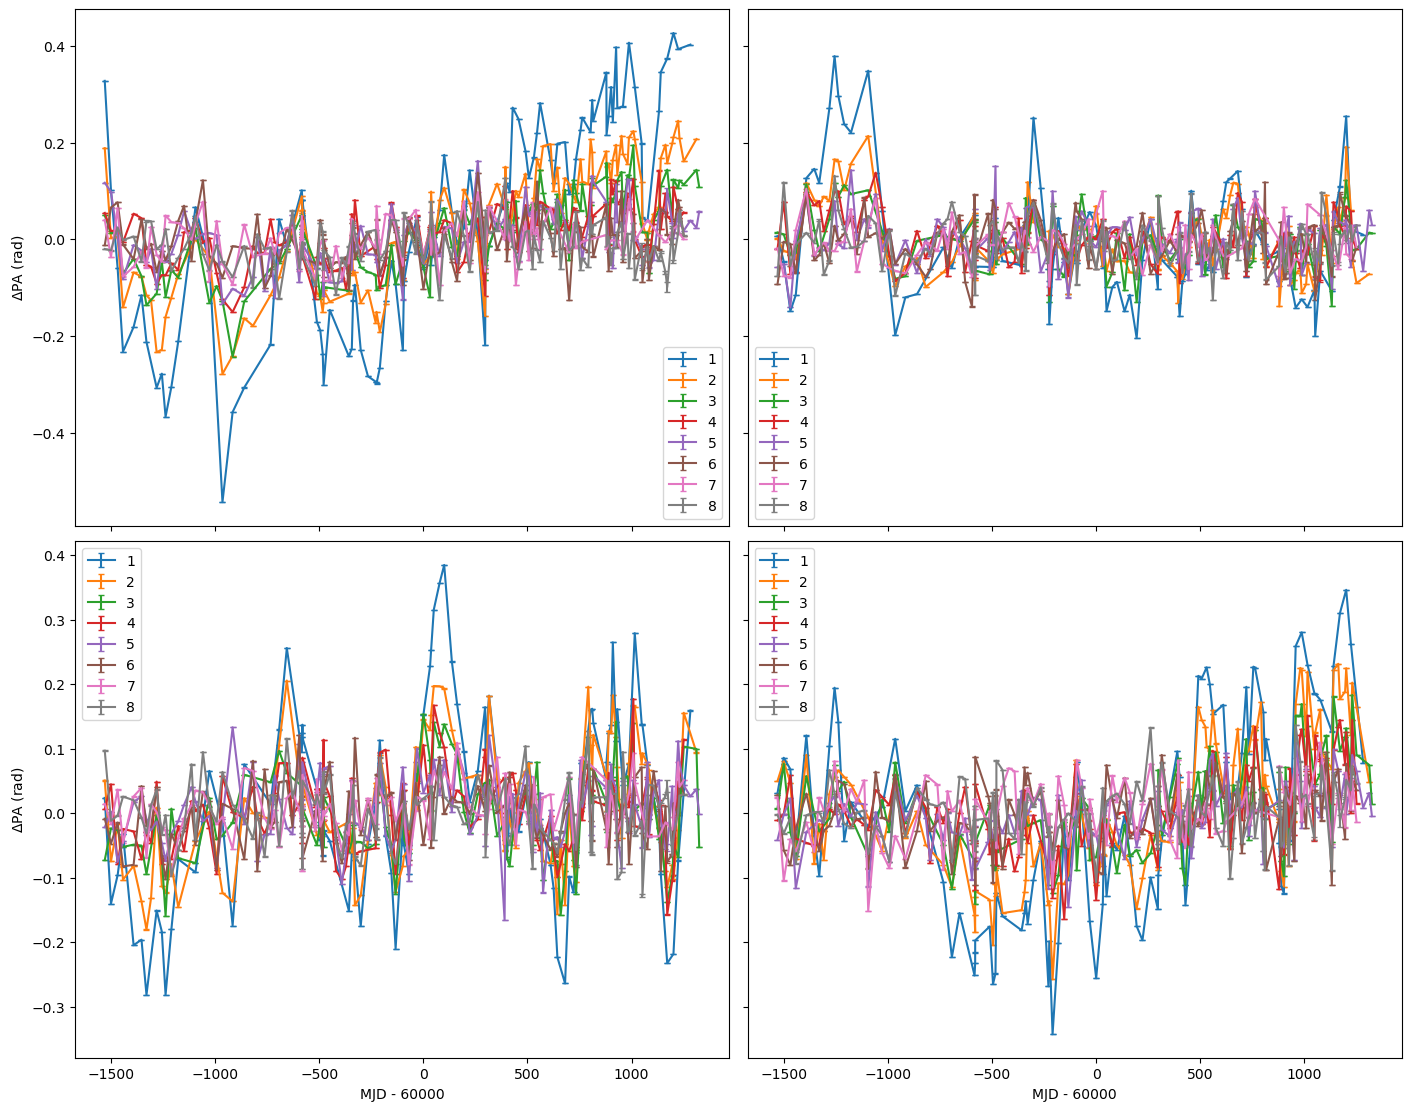

In [ ]:
sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # fix parameters to reasonable value
        # params = {
        #     'J0835-4510_efac':4.0,#7.405,
        #     'J0835-4510_log10_ecorr':-2.006,
        #     'J0835-4510_log10_t2equad':-2.287,
        #     'J0835-4510_rednoise_gamma':2.0, 
        #     'J0835-4510_rednoise_log10_A':-9,
        #     'J0835-4510_rmgp_gamma':1.118,
        #     'J0835-4510_rmgp_log10_A':-8.140
        #     }
        params = {
        'J0835-4510_efac':6.635,
        'J0835-4510_log10_ecorr':-1.603,
        'J0835-4510_log10_t2equad':-2.252,
        'J0835-4510_rednoise_gamma':1.403,
        'J0835-4510_rednoise_log10_A':-9.615,
        'J0835-4510_rmgp_gamma':1.192,
        'J0835-4510_rmgp_log10_A':-8.135
        }

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = sampler(key, params)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

In [ ]:
sampler = infer.MCMC(infer.NUTS(numpyro_model),
                     num_warmup=200, num_samples=300)
sampler.run(jax.random.PRNGKey(42))

sample: 100%|██████████| 500/500 [2:57:47<00:00, 21.34s/it, 127 steps of size 4.47e-02. acc. prob=0.88]  


In [ ]:
raw_samples = sampler.get_samples()['raw']
# print(raw_samples)

p_fit = {}
for i, name in enumerate(logL.params):
    col = raw_samples[:, i]
    print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  bounds={bounds[i]}')
    p_fit[name] = col.mean()

print(p_fit)
print(f'{logL(p_fit):e}')

J0835-4510_efac                mean=+6.635  std=2.413  bounds=[0.1, 10]
J0835-4510_log10_ecorr         mean=-1.603  std=0.033  bounds=[-3, -1]
J0835-4510_log10_t2equad       mean=-2.252  std=0.204  bounds=[-3.5, -1.5]
J0835-4510_rednoise_gamma      mean=+1.403  std=0.979  bounds=[0, 4]
J0835-4510_rednoise_log10_A    mean=-9.615  std=0.274  bounds=[-10, -8]
J0835-4510_rmgp_gamma          mean=+1.192  std=0.244  bounds=[0, 2]
J0835-4510_rmgp_log10_A        mean=-8.135  std=0.046  bounds=[-9, -7]
{'J0835-4510_efac': Array(6.63513221, dtype=float64), 'J0835-4510_log10_ecorr': Array(-1.60322567, dtype=float64), 'J0835-4510_log10_t2equad': Array(-2.25244248, dtype=float64), 'J0835-4510_rednoise_gamma': Array(1.40349858, dtype=float64), 'J0835-4510_rednoise_log10_A': Array(-9.61481815, dtype=float64), 'J0835-4510_rmgp_gamma': Array(1.19228014, dtype=float64), 'J0835-4510_rmgp_log10_A': Array(-8.13492785, dtype=float64)}
2.618152e+03


<class 'jaxlib._jax.ArrayImpl'>


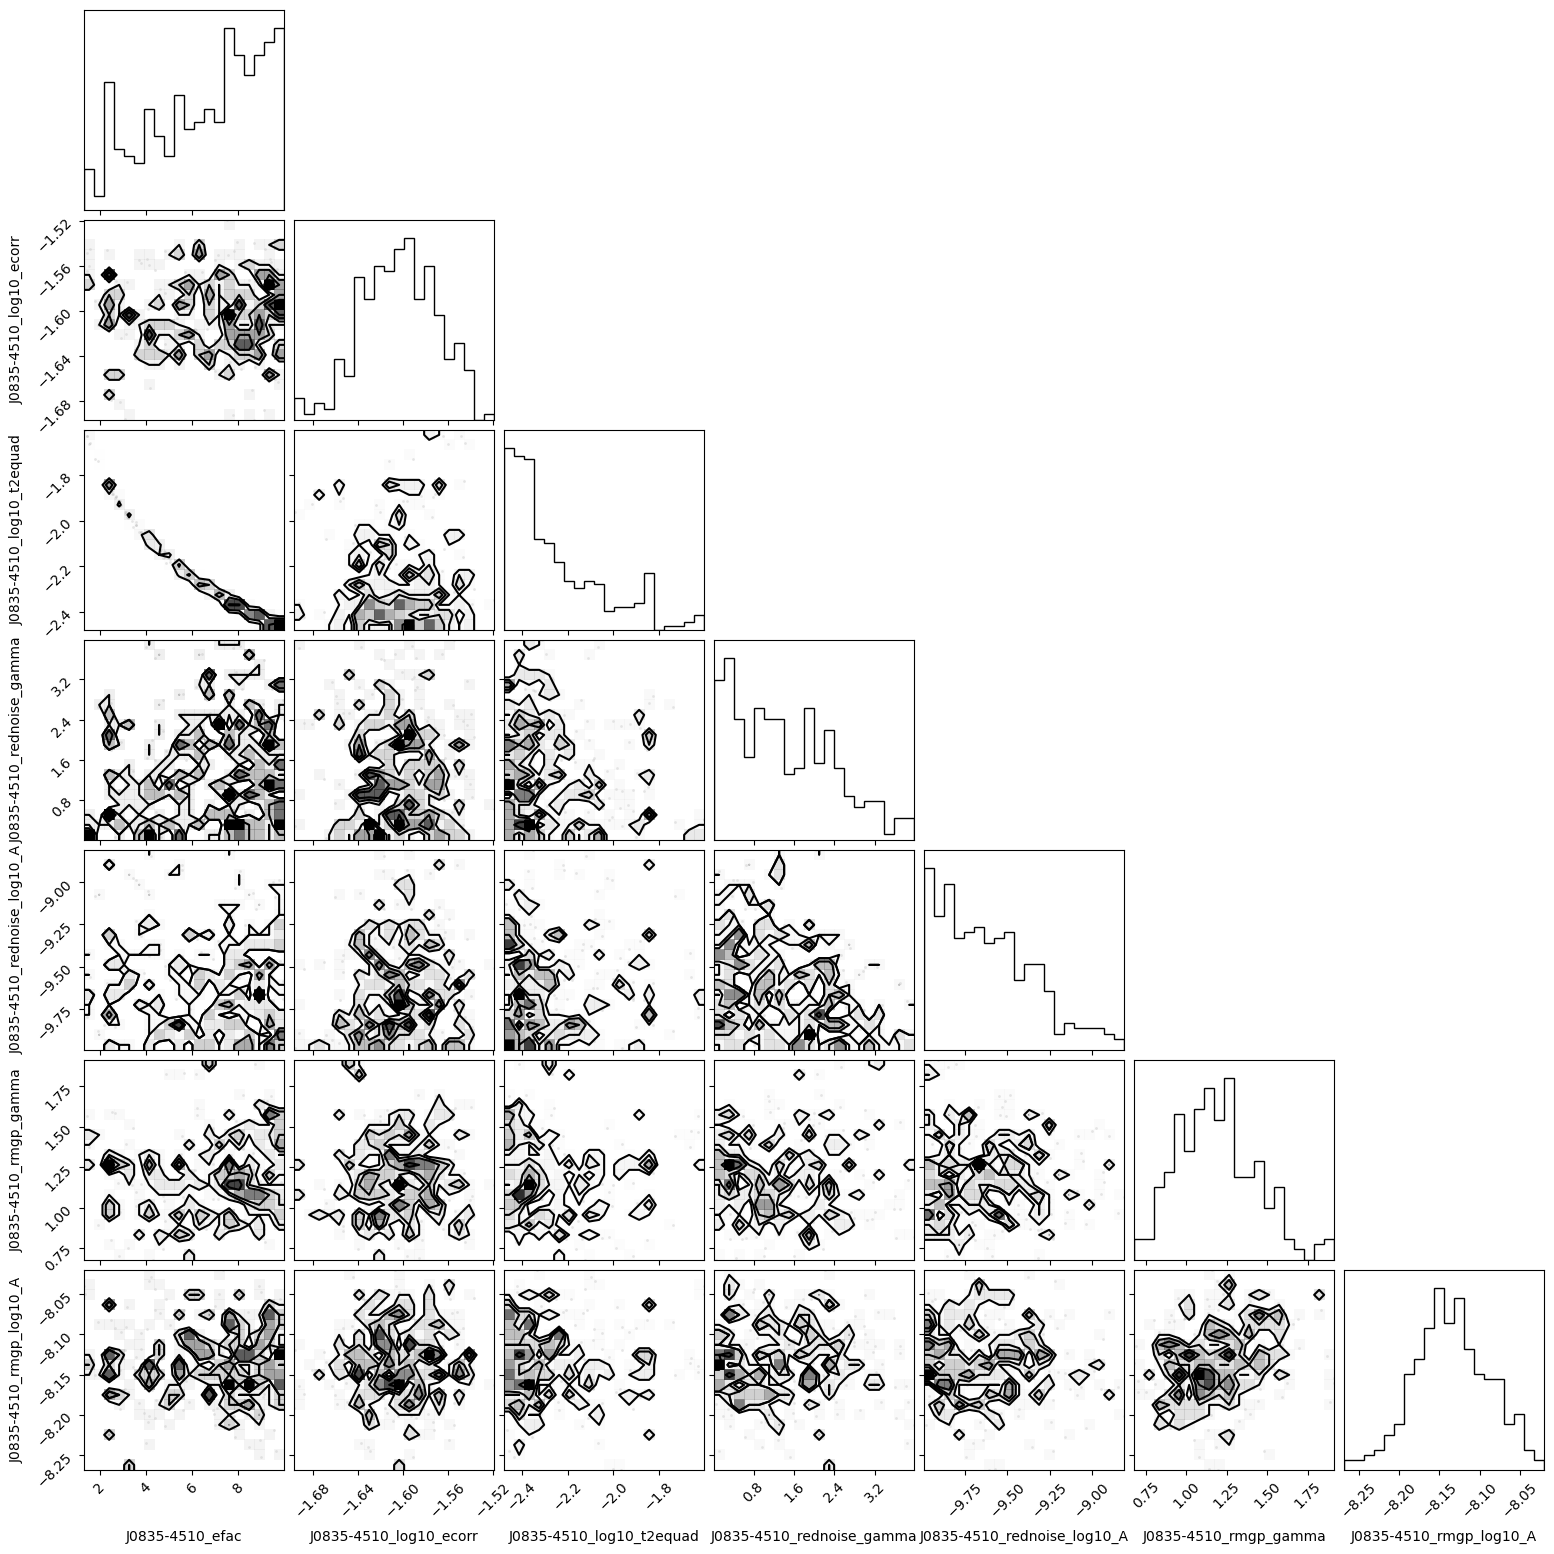

In [ ]:
figure = corner.corner(
    np.array(raw_samples),
    labels=logL.params
    )
print(type(raw_samples))

In [ ]:
# sampler = m_red.sample

fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_red.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

NameError: name 'plt' is not defined

#### Time-domain RM noise

In [ ]:
# n_obs = ds.quantize(psr.toas, dt=1.0)[-1]; print(n_obs)

# m_RM_t = ds.PulsarLikelihood([psr.residuals,
#                          ds.makenoise_measurement_simple(psr),
#                          ds.makegp_ecorr_simple(psr),
#                          ds.makegp_fftcov_dm(psr, ds.powerlaw, components=23, oversample=6, name='dmgp') # Label RM as DM to get prior
#                          ])
# print(m_RM_t.logL.params)

In [ ]:
# p0 = ds.sample_uniform(m_RM.logL.params)
# print(p0)
# print(f'Noise:            {m.logL(p0):e}')
# print(f'Noise+ECORR:      {m_ecorr.logL(p0):e}')
# print(f'Noise+ECORR+RM:   {m_RM.logL(p0):e}')
# print(f'Noise+ECORR+RM_t: {m_RM.logL(p0):e}')

In [ ]:
# logL_RM_t = m_RM_t.logL

# # static layout shared by every Params built inside the model
# layout, size = make_layout(logL_RM_t.params)

# # flat uniform bounds, one entry per (scalar) parameter
# bounds = [prior.getprior_uniform(p) for p in logL_RM_t.params]
# lo = jnp.array([b[0] for b in bounds])
# hi = jnp.array([b[1] for b in bounds])

# def numpyro_model_RM_t():
#     raw = numpyro.sample('raw', dist.Uniform(lo, hi))   # one (P,) array site
#     numpyro.factor('logl', logL_RM_t(Params(raw, layout)))

In [ ]:
# sampler_RM_t = infer.MCMC(infer.NUTS(numpyro_model_RM_t),
#                      num_warmup=200, num_samples=200)
# sampler_RM_t.run(jax.random.PRNGKey(42))

In [ ]:
# raw_samples = sampler.get_samples()['raw']
# # print(raw_samples)

# p_fit = {}
# for i, name in enumerate(logL.params):
#     col = raw_samples[:, i]
#     print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}')
#     p_fit[name] = col.mean()

# print(p_fit)
# print(f'{logL(p_fit):e}')